# 02 · Comparing Timepoints & Naming the Anatomy

Uses `mri_utils.py` (`mu`). Two questions: **did the lesion grow or shrink** between 16 dpm (acute) and 11 dpm (subacute), and **which brain structures / arteries** does it involve?

In [1]:
import sys
from pathlib import Path
if ".." not in sys.path:
    sys.path.append("..")

DATA_DIR = Path("data") if Path("data").is_dir() else Path("../data") if Path("../data").is_dir() else Path(".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

import mri_utils as mu


## 2.1 Two Timepoints, One Grid

`dpm` = days pre-mortem, so **16 dpm is earlier**, **11 dpm is later**. `iv16_DWI` and `iv11_DWI` already share one reference grid, so they can be compared voxel-for-voxel directly.

lesion rule: above 150 (204 raw components, 121 kept >= 10 voxels)


lesion rule: above 150 (207 raw components, 123 kept >= 10 voxels)
label_a                             16dpm
label_b                             11dpm
mean_intensity_16dpm_in_mask_a      164.58892822265625
mean_intensity_11dpm_in_mask_a      148.1665802001953
volume_mL_16dpm                     161.66
volume_mL_11dpm                     148.4
dice                                0.417
jaccard                             0.264
volume_change_mL                    -13.26

16dpm lesion:


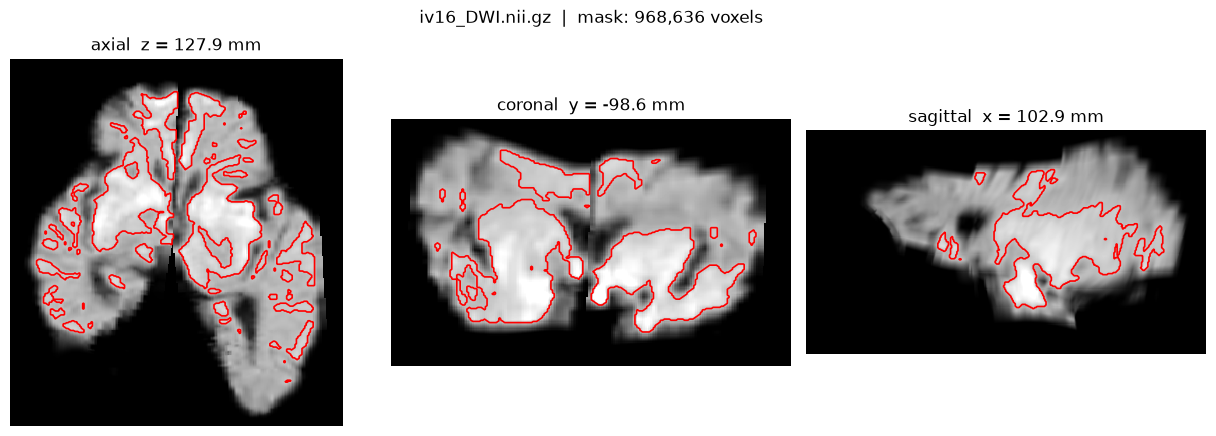

11dpm lesion:


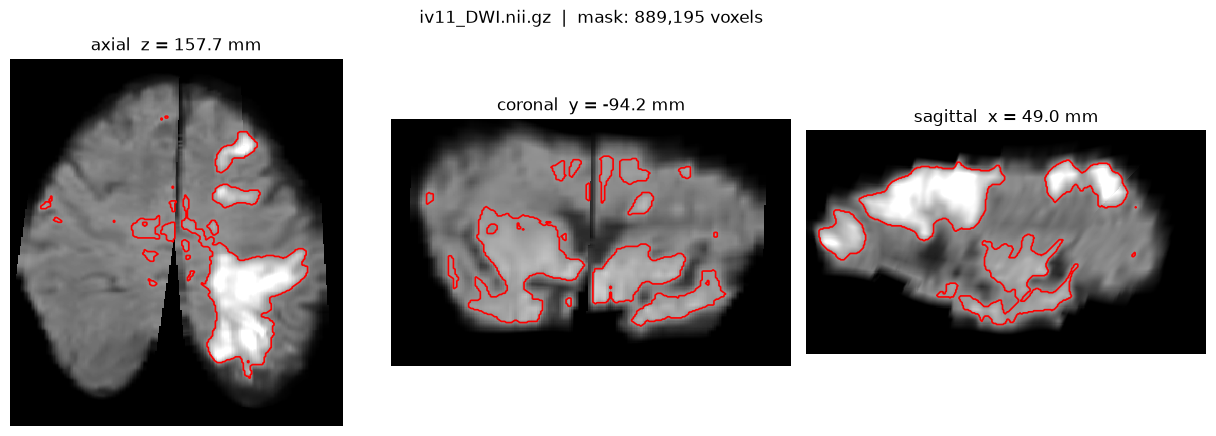

In [2]:
iv16 = mu.load_mri(str(DATA_DIR / "iv16_DWI.nii.gz"))
iv11 = mu.load_mri(str(DATA_DIR / "iv11_DWI.nii.gz"))

brain16 = mu.brain_mask(iv16)
brain11 = mu.brain_mask(iv11)
lesion16 = mu.lesion_mask(iv16, brain16, threshold=150, direction="above")
lesion11 = mu.lesion_mask(iv11, brain11, threshold=150, direction="above")

change = mu.compare_mri_volumes(iv16, iv11, mask_a=lesion16, mask_b=lesion11, label_a="16dpm", label_b="11dpm")
for k, v in change.items():
    if k != "difference":
        print(f"{k:35s} {v}")

print()
print("16dpm lesion:")
fig = mu.show_mri(iv16, mask=lesion16)
plt.show()
print("11dpm lesion:")
fig = mu.show_mri(iv11, mask=lesion11)
plt.show()

### 2.1b One Lesion or Several?

Total volume change can hide fragmentation. `mu.lesion_stats(mask, mri)` reports volume + hemisphere **per connected component**, not just the total.

In [3]:
stats16 = mu.lesion_stats(lesion16, iv16)
stats11 = mu.lesion_stats(lesion11, iv11)

for name, s in (("16dpm", stats16), ("11dpm", stats11)):
    print(f"--- {name}: {s['total_mL']} mL across {s['n_components']} connected component(s), "
          f"side = {s.get('side (by centroid x_RAS)', 'n/a')} ---")

print("\n16dpm components (largest first):")
display(stats16["components"].head(5))
print("\n11dpm components (largest first):")
display(stats11["components"].head(5))


--- 16dpm: 161.66 mL across 121 connected component(s), side = right ---
--- 11dpm: 148.4 mL across 123 connected component(s), side = right ---

16dpm components (largest first):


,component,voxels,mL,x_RAS,y_RAS,z_RAS
0,1,485270,80.99,107.2,-92.5,134.5
1,2,462085,77.12,51.2,-104.1,121.7
2,64,2426,0.40,114.0,-110.7,168.7
3,97,1696,0.28,103.6,-140.0,136.3
4,15,1456,0.24,124.9,-58.1,139.3



11dpm components (largest first):


,component,voxels,mL,x_RAS,y_RAS,z_RAS
0,44,438991,73.26,45.7,-148.7,150.8
1,32,182816,30.51,112.4,-94.1,127.8
2,52,174613,29.14,54.2,-103.9,116.8
3,28,56327,9.40,52.8,-78.1,162.4
4,21,6333,1.06,60.6,-57.1,144.6


### 2.2 Interpretation

Lesion volume: **161.66 mL (16dpm) → 148.40 mL (11dpm)**, a **-13.26 mL** change. But Dice overlap between the two masks is only **0.417** — a lot of the lesion *relocated*, it didn't just shrink in place.

**Caveat**: `lesion_stats` reports hemisphere "right" by raw RAS sign, but `manifest["notes"]["coverage"]` and the arterial atlas (§2.4) both say **left** — likely a DWI affine left/right convention quirk (unverified). Trust the atlas-name laterality, not the raw sign, until someone checks the source DICOM.

## 2.3 Naming the Damage

`manifest.json` ships pre-aligned label volumes — `lab_mni.bin` (anatomy) and `lab_art.bin` (arterial territory) — on the same grid as the imaging. `mu.regional_lesion_burden(core_mask, labels, lookup, manifest, lr_swap=...)` reports % infiltration per region. `lr_swap=True` corrects a known mirroring bug in the arterial atlas (`manifest["notes"]["arterial_lr"]`).

In [4]:
import json

manifest = json.load(open(DATA_DIR / "manifest.json"))
lab_mni = mu.load_manifest_volume(manifest, "mni", data_dir=DATA_DIR)
lab_art = mu.load_manifest_volume(manifest, "art", data_dir=DATA_DIR)

# Recreate the validated ischemic core (DWI >= 150 & ADC <= 750)
pair_11 = mu.load_diffusion_pair(str(DATA_DIR / "iv11_DWI.nii.gz"), str(DATA_DIR / "iv11_ADC.nii.gz"))
masks_11 = mu.restricted_diffusion_lesion(pair_11, dwi_threshold=150.0, adc_max=750.0, return_all=True)

cols = ["name", "region_volume_mL", "lesion_volume_mL", "pct_region_infiltrated"]
burden_mni = mu.regional_lesion_burden(masks_11["core"], lab_mni, manifest["atlas"]["mni"], manifest)
burden_art = mu.regional_lesion_burden(masks_11["core"], lab_art, manifest["atlas"]["art"], manifest, lr_swap=True)

print("--- Anatomical regions (MNI), top 5 by lesion volume ---")
display(burden_mni[cols].head(5))

print("\n--- Arterial territories (JHU), top 5 ---")
display(burden_art[cols].head(5))

--- Anatomical regions (MNI), top 5 by lesion volume ---


,name,region_volume_mL,lesion_volume_mL,pct_region_infiltrated
0,white matter of forebrain,365.92,32.23,8.81
1,inferior occipital gyrus,38.35,10.02,26.14
2,superior occipital gyrus,27.86,7.34,26.33
3,putamen,11.97,5.88,49.09
4,supraparietal lobule,19.00,4.64,24.44



--- Arterial territories (JHU), top 5 ---


,name,region_volume_mL,lesion_volume_mL,pct_region_infiltrated
0,occipital pars of middle cerebral artery left,57.44,17.03,29.64
1,parietal pars of middle cerebral artery left,77.00,13.55,17.59
2,anterior cerebral artery left,95.75,10.95,11.44
3,occipital pars of posterior cerebral artery left,62.05,9.29,14.97
4,frontal pars of middle cerebral artery left,103.86,7.66,7.37


### 2.4 Clinical Attribution

- **Putamen 49.1% infiltrated** — classic deep-nuclei MCA pattern.
- Occipital & superior parietal cortex each ~24–26% infiltrated.
- Arterial supply: **left MCA** (occipital/parietal) + **left ACA**.

**Next**: Notebook 03 maps this lesion onto physical histology blocks you'd actually cut.